In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from src.transmission_function import TransmissionFunction
from src.single_theta_flux import SingleThetaFlux
from src.telescope import RootTelescopeConstructor

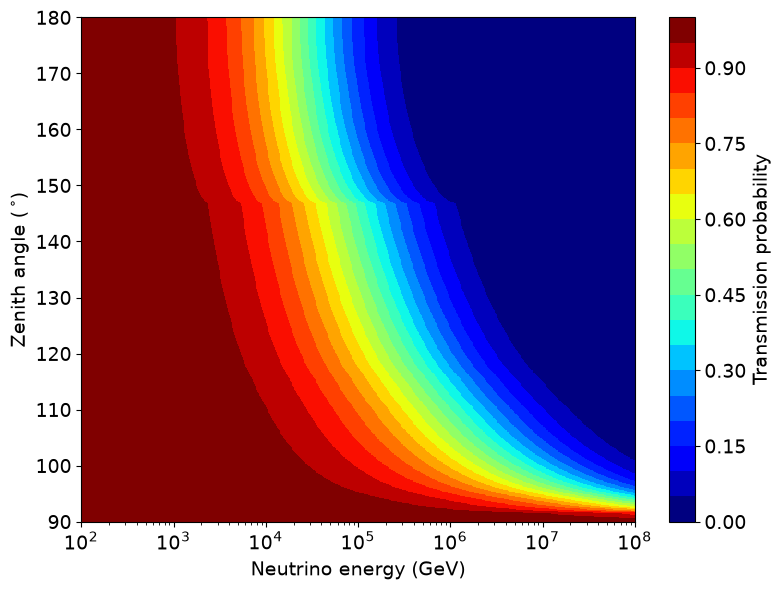

In [2]:
lg_energy = np.linspace(0, 10, 1000)
zenith = np.linspace(np.pi/2+1e-5, np.pi-1e-5, 900)
zenith_scale = np.linspace(90, 180, 900)
energy = 10**lg_energy

gammas = np.linspace(2, 4, 5)
res = np.zeros([900, 1000])

for gamma in gammas:
    telescope = RootTelescopeConstructor("baikal_2021", "hnu").get()

    tf = TransmissionFunction(nuFate_method=1)

    flux = tf.energy**(-gamma)

    for i, z_i in enumerate(zenith):
        stf = SingleThetaFlux(initial_flux=flux, telescope=telescope,
                                zenith=z_i, tf=tf)

        conv_f = stf.convoluted_flux()
        interp_f = stf.interpolated_flux(conv_f)

        res[i, :] += interp_f(energy)

res /= gammas.size
copper = mpl.colormaps['jet'].resampled(20)

plt.figure(figsize=(8, 6))
plt.pcolormesh(energy, zenith_scale, res, cmap=copper, rasterized=True)
plt.xlim(1e2, 1e8)
plt.xlabel("Neutrino energy (GeV)", fontsize=14)
plt.ylabel(r"Zenith angle $({}^\circ\!)$", fontsize=14)
plt.tick_params(labelsize=14)
plt.ylim(90, 180)
cb = plt.colorbar(ticks=[0, 0.15, 0.30, 0.45, 0.60, 0.75, 0.90])
cb.set_label(label="Transmission probability", size=14)
cb.ax.tick_params(labelsize=14)
plt.xscale('log')

plt.tight_layout()
plt.show()